# Tox21 Applications: which compounds look unusual?

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/CompOmics/ML_AI_Analytical_Chemistry_Course/blob/main/04_Applications/notebooks/TD3_tox21_student.ipynb)

TD1 and TD2 predicted an SR-MMP assay class. Here we ask which compounds
have unusual combinations of the same eight descriptors. An outlier is
unusual relative to a reference group; a flag requests closer review.
It does not predict assay activity.

As in TD1, Active and Inactive refer only to the recorded SR-MMP result,
not an overall judgement about human toxicity or safety.

Run the four setup cells in section 1, then focus on the outlier reference group
in section 2. All code is supplied; write your answers in the Your answer
text cells. Use the standard CPU runtime in Colab.

## 1. Quick recap and setup

Reuse TD1's Tox21 data and eight descriptors. The preparation below
keeps the same 5,804 labelled, readable compounds. Missing assay results
remain unknown and are excluded, along with unreadable structures.

Install the same fixed RDKit version as TD1.

In [1]:
%pip -q install rdkit==2025.9.6

Load the tools for tables, descriptor calculations, plots and models.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from rdkit import Chem, RDLogger
from rdkit.Chem import Descriptors
from sklearn.model_selection import train_test_split
from sklearn.ensemble import IsolationForest
RDLogger.DisableLog("rdApp.*")

Read and clean the same data as TD1. The output checks the retained
record count and shows that Inactive results are more common than Active.

In [3]:
DATA_URL = "https://deepchemdata.s3-us-west-1.amazonaws.com/datasets/tox21.csv.gz"
raw_data = pd.read_csv(DATA_URL)
data = raw_data.dropna(subset=["SR-MMP", "smiles"]).copy()
data["molecule"] = data["smiles"].map(Chem.MolFromSmiles)
readable = data["molecule"].notna()
print("Structures that could not be read:", (~readable).sum())
data = data.loc[readable].copy()
labels = data["SR-MMP"].map({0: "Inactive", 1: "Active"})
print("Records kept:", len(data))
print(labels.value_counts())

Structures that could not be read: 6
Records kept: 5804
SR-MMP
Inactive    4886
Active       918
Name: count, dtype: int64


Calculate the same eight descriptors and show a feature-table reminder.
The assay label stays separate; the models receive the unrounded values.

In [4]:
features = pd.DataFrame(index=data.index)
features["Mass"] = data["molecule"].map(Descriptors.MolWt)
features["LogP"] = data["molecule"].map(Descriptors.MolLogP)
features["H_donors"] = data["molecule"].map(Descriptors.NumHDonors)
features["H_acceptors"] = data["molecule"].map(Descriptors.NumHAcceptors)
features["Polar_area"] = data["molecule"].map(Descriptors.TPSA)
features["Rotatable_bonds"] = data["molecule"].map(Descriptors.NumRotatableBonds)
features["Aromatic_rings"] = data["molecule"].map(Descriptors.NumAromaticRings)
features["Heavy_atoms"] = data["molecule"].map(Descriptors.HeavyAtomCount)
features.head().round(2)

,Mass,LogP,H_donors,H_acceptors,Polar_area,Rotatable_bonds,Aromatic_rings,Heavy_atoms
0,258.32,1.34,1,5,82.28,3,2,16
1,204.23,1.30,1,2,49.41,2,1,15
3,276.42,3.75,1,2,32.34,7,1,20
4,206.03,-0.99,5,3,135.29,2,0,11
5,290.44,4.82,0,4,36.92,7,0,20


## 2. Choose the reference group

Reuse TD1's split: 4,643 training records and the same 1,161 test records.
The whole training group is our reference, including both Active and
Inactive compounds. Here usual means familiar descriptor patterns, not
Inactive or safe. Labels help form the split but do not teach the detector.

If you did strawberry Applications, its reference group was labelled
Strawberry. Our question here needs a different reference group.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    features, labels, test_size=0.20, random_state=42, stratify=labels
)
print("Training reference samples:", len(X_train))
print("Test samples:", len(X_test))

Training reference samples: 4643
Test samples: 1161


This returns to the original Foundations training group, including the
validation records from Evaluation. The detector and flagging setting are
fixed in advance, so we are not using validation to compare alternatives.

### Stop and explain 1

Why does the reference group include both assay classes? Why should the
test compounds be excluded while the detector learns familiar patterns?

Your answer:

Write your answer here in words.

## 3. Teach one outlier detector

An isolation forest makes many random questions about the descriptors.
Unusual records can often be separated from most reference examples with
fewer questions. The forest combines this information to flag measurements.
Evaluation's random forest learned class labels; this forest does a different job.

`fit(X_train)` receives features, not assay labels. The fixed teaching setting
`contamination=0.05` places a boundary so that about 5% of the training
reference records are flagged. It does not measure the fraction of toxic
compounds or require that 5% of future records be flagged. Keep it unchanged.

In [6]:
detector = IsolationForest(contamination=0.05, random_state=42)
detector.fit(X_train)

,"contamination contamination: 'auto' or float, default='auto'The amount of contamination of the data set, i.e. the proportionof outliers in the data set. Used when fitting to define the thresholdon the scores of the samples.- If 'auto', the threshold is determined as in the original paper.- If float, the contamination should be in the range (0, 0.5]... versionchanged:: 0.22 The default value of ``contamination`` changed from 0.1 to ``'auto'``.",0.05
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo-randomness of the selection of the featureand split values for each branching step and each tree in the forest.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"n_estimators n_estimators: int, default=100The number of base estimators in the ensemble.",100
,"max_samples max_samples: ""auto"", int or float, default=""auto""The number of samples to draw from X to train each base estimator.- If int, then draw `max_samples` samples.- If float, then draw `max_samples * X.shape[0]` samples.- If ""auto"", then `max_samples=min(256, n_samples)`.If max_samples is larger than the number of samples provided,all samples will be used for all trees (no sampling).",'auto'
,"max_features max_features: int or float, default=1.0The number of features to draw from X to train each base estimator.- If int, then draw `max_features` features.- If float, then draw `max(1, int(max_features * n_features_in_))` features.Note: using a float number less than 1.0 or integer less than number offeatures will enable feature subsampling and leads to a longer runtime.",1.0
,"bootstrap bootstrap: bool, default=FalseIf True, individual trees are fit on random subsets of the trainingdata sampled with replacement. If False, sampling without replacementis performed.",False
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for :meth:`fit`. ``None`` means 1unless in a :obj:`joblib.parallel_backend` context. ``-1`` means usingall processors. See :term:`Glossary <n_jobs>` for more details.",None
,"verbose verbose: int, default=0Controls the verbosity of the tree building process.",0
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fitand add more estimators to the ensemble, otherwise, just fit a wholenew forest. See :term:`the Glossary <warm_start>`... versionadded:: 0.21",False
Name,Type,Value
estimator_ estimator_: :class:`~sklearn.tree.ExtraTreeRegressor` instanceThe child estimator template used to create the collection offitted sub-estimators... versionadded:: 1.2 `base_estimator_` was renamed to `estimator_`.,ExtraTreeRegressor,ExtraTreeRegr...ndom_state=42)


### Stop and explain 2

Does 0.05 mean that 5% of compounds are toxic? Must 5% of the test group
be flagged? Explain what this setting actually controls.

Your answer:

Write your answer here in words.

## 4. Flag records excluded from training

`predict` uses the eight test features without their assay labels. It returns
`-1` for flagged records and `1` for the rest. `== -1` makes a simple flag:
True means flagged, False means not flagged. `sum()` counts True flags.

In [7]:
flags = detector.predict(X_test) == -1
review = pd.DataFrame({"Flagged": flags}, index=X_test.index)
print("Compounds checked:", len(review))
print("Flagged for review:", review["Flagged"].sum())
review.head()

Compounds checked: 1161
Flagged for review: 57


,Flagged
4867,False
6532,False
924,False
3012,False
5043,False


Each dot below is one test compound. The axes show molecular weight and
predicted LogP; orange points are flagged. The detector used all eight
descriptors, so separation in this two-feature view need not be obvious.
Larger values do not automatically mean more toxic compounds.

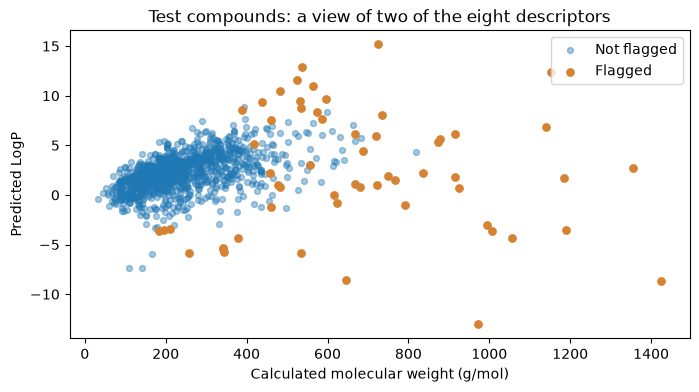

In [8]:
plt.figure(figsize=(8, 4))
plt.scatter(X_test.loc[~flags, "Mass"], X_test.loc[~flags, "LogP"],
            label="Not flagged", alpha=0.4, s=18)
plt.scatter(X_test.loc[flags, "Mass"], X_test.loc[flags, "LogP"],
            label="Flagged", color="#D58232", s=28)
plt.xlabel("Calculated molecular weight (g/mol)")
plt.ylabel("Predicted LogP")
plt.title("Test compounds: a view of two of the eight descriptors")
plt.legend()
plt.show()

Inspect the first flagged row in the test table. The table compares its
descriptor values with the training averages. `loc` selects the row;
`mean()` gives an average per feature. These averages are visual reference
values, not acceptance limits. Do not compare absolute differences across
descriptors with different units. One example does not represent all flags.

In [9]:
example_id = review.loc[review["Flagged"]].index[0]
comparison = pd.DataFrame({
    "Training average": X_train.mean(),
    "Flagged example": X_test.loc[example_id]
})
print("Example source ID:", data.loc[example_id, "mol_id"])
comparison.round(2)

Example source ID: TOX26696


,Training average,Flagged example
Mass,261.99,680.74
LogP,2.18,0.82
H_donors,1.22,5.00
H_acceptors,3.38,11.00
Polar_area,58.56,245.03
Rotatable_bonds,4.17,13.00
Aromatic_rings,0.98,3.00
Heavy_atoms,17.59,47.00


### Stop and explain 3

Compare the example's Mass and Polar_area with their own training averages.
Does this table prove that the structure is wrong, or that the compound is toxic?
Give one useful follow-up check.

Your answer:

Write your answer here in words.

## 5. Reveal the assay labels

Add the known test labels only after flagging. `crosstab` counts flagged
and unflagged records for each assay class. As in the earlier mistake tables,
rows are reference labels. Here columns are Not flagged and Flagged,
not predicted assay classes. Active is not a ground-truth label for outliers.

In [10]:
review["Reference"] = y_test
counts = pd.crosstab(review["Reference"], review["Flagged"])
counts = counts.rename(columns={False: "Not flagged", True: "Flagged"})
counts = counts.reindex(["Inactive", "Active"])
counts

Flagged,Not flagged,Flagged
Reference,,
Inactive,932,45
Active,172,12


The bars show the same counts. The classes have different sizes: compare
each flagged count with the total of its own row, rather than comparing
bar heights alone. This is not a classification accuracy chart.

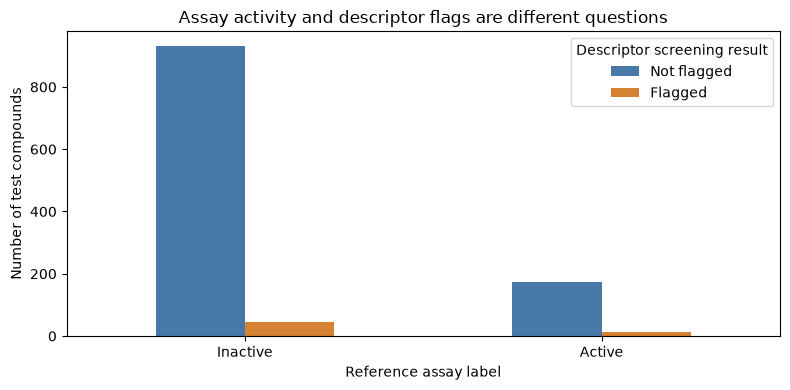

In [11]:
counts.plot.bar(color=["#4878A8", "#D58232"], rot=0, figsize=(8, 4))
plt.ylabel("Number of test compounds")
plt.xlabel("Reference assay label")
plt.title("Assay activity and descriptor flags are different questions")
plt.legend(title="Descriptor screening result")
plt.tight_layout()
plt.show()

### Stop and explain 4

How many Active and Inactive compounds were flagged? How many Active
compounds were not flagged? Why are these not false-positive and
false-negative counts for an assay classifier?

Your answer:

Write your answer here in words.

## 6. Plan the follow-up

An unflagged compound can still be Active in SR-MMP. A flagged compound
can be Inactive. An assay prediction and an outlier flag answer different
questions; neither certifies human safety.

The test group was used earlier in the series. Reuse here is a classroom
demonstration, not fresh independent validation. New chemical families
require further checks before routine use of these models.

### Stop and explain 5

A colleague says, “We can treat every unflagged compound as safe.”
Write two or three sentences explaining what the results support and
what experimental follow-up is still needed.

Your answer:

Write your answer here in words.

## Data and reuse

These practicals use the public DeepChem Tox21 CSV, not a new experimental
dataset. Of 7,831 source records, 2,021 have no SR-MMP result and six more
have structures unreadable with the fixed RDKit version. The 5,804 retained
records contain 4,886 Inactive and 918 Active results. Instructors checked
that no identical canonical structure is repeated in this retained subset.
Different structures can still have identical values for these eight descriptors.

These random teaching splits are not DeepChem's default scaffold split:
related chemical families can occur in both training and test groups.
They do not establish performance on unfamiliar chemical families. No
fragments, charges or salts are removed from the recorded structures.

- [Tox21 challenge: assay tasks and original data context](https://tripod.nih.gov/tox21/challenge/about.jsp).
- [DeepChem Tox21 loader and source-file address](https://github.com/deepchem/deepchem/blob/master/deepchem/molnet/load_function/tox21_datasets.py).
- [RDKit molecular descriptor documentation](https://www.rdkit.org/docs/GettingStartedInPython.html#list-of-available-descriptors).

We read DeepChem's public data file directly with pandas and calculate
descriptors with RDKit. Installing the DeepChem Python package is not
required. These exercises do not reproduce the Tox21 challenge benchmark.
An assay prediction or an outlier flag cannot certify human safety.